In [1]:
# =============================================================================
# Projeto de Inteligência Artificial - 7ºJ SI Noite
# Predição de Hospitalização em Casos Confirmados de Dengue (SP)
#
# Integrantes do grupo:
#   - Geovanna da Silva Lima - RA: 10420059
#   - Pedro Henrique Mansano Fernandes - RA: 10388037
#   - Priscila Raquel Herculano Correia - RA: 10420400
#
# Síntese do conteúdo do arquivo:
#   Notebook de Modelagem e Avaliação para o
#   problema de predição de hospitalização em pacientes com dengue
#   confirmada, utilizando dados públicos do SINAN/DATASUS (UF: SP).
# Histórico de alterações:
#   | Data       | Autor                    | Descrição                                     |
#   |------------|--------------------------|-----------------------------------------------|
#   | 2026-11-11 | Pedro Henrique           | Criação inicial do notebook                   |
#   | 2026-11-11 | Pedro Henrique           | Remoção de CS_RACA dos preditores             |
#   | 2026-11-12 | Pedro Henrique           | Remoção de CS_ESCOL_N dos preditores          |
#   | 2026-11-12 | Pedro Henrique           | Remoção de CS_SEXO dos preditores             |
#   | 2026-11-12 | Pedro Henrique           | Remoção das seções de ablação e equidade      |
# ==========================================================================================|

# Predição de Hospitalização em Casos Confirmados de Dengue — Modelagem (N2)

Continuação do `analise_exploratoria_dengue.ipynb` (N1), que gerou
`dengue_sp_treino.csv` (32.000 casos) e `dengue_sp_teste.csv` (8.000 casos),
ambos com ~4,7% de hospitalizados.

**Protocolo de avaliação:**

1. Modelo, hiperparâmetros e **limiar de decisão** são escolhidos **só no treino**,
   com validação cruzada estratificada (5 partições).
2. O teste é usado **uma única vez**, ao final, com intervalos de confiança por
   *bootstrap*.
3. O pré-processamento fica dentro de um `Pipeline`, evitando vazamento de
   informação entre as partições.

**Métricas:** com ~95% de negativos, a acurácia é enganosa (prever sempre "não
hospitalizado" acerta 95%). Usamos AUC-ROC, AUC-PR (*average precision*),
recall, precisão e F1 da classe positiva, priorizando o recall pelo custo de um
falso negativo em contexto clínico.

## 1. Configuração do ambiente

In [2]:
# Bibliotecas: pandas/numpy (dados), matplotlib/seaborn (gráficos),
# scikit-learn (modelos, validação e métricas).
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 100)

In [3]:
# >>> PREENCHER AQUI: caminhos e parâmetros <<<
# BASE_DIR aponta para a pasta dengue_IA/, seja o notebook executado a partir
# de notebooks/ (padrão do Jupyter/VS Code) ou da raiz do projeto.
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TREINO_PATH = BASE_DIR / "notebooks" / "dengue_sp_treino.csv"
TESTE_PATH = BASE_DIR / "notebooks" / "dengue_sp_teste.csv"

SEED = 42            # mesma semente do notebook de EDA
N_FOLDS = 5          # partições da validação cruzada
META_RECALL = 0.80   # recall mínimo desejado para a classe "hospitalizado"
N_BOOTSTRAP = 1000   # reamostragens para os intervalos de confiança

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

## 2. Carregamento dos dados preparados

**Variáveis sociodemográficas excluídas dos preditores:**

- **`CS_RACA` (raça/cor):** a menor taxa de internação registrada entre pretos e
  pardos tende a refletir desigualdade de **acesso** a leitos, e não menor
  gravidade; um modelo que usa a variável aprende e reproduz essa desigualdade.
- **`CS_ESCOL_N` (escolaridade):** quase metade dos registros não tem a
  informação (28,5% ignorado e 18,3% não preenchido na EDA); é um indicador
  socioeconômico, com o mesmo risco de refletir acesso, e não gravidade; e
  categorias como "analfabeto" e "não se aplica" (crianças) se confundem com a
  idade, que já está no modelo.
- **`CS_SEXO` (sexo):** a taxa de internação é praticamente igual entre os
  sexos (4,66% no feminino e 4,75% no masculino na EDA), então a variável não
  traz informação útil.

**Premissa:** assumimos que `DIAS` e `LEUCOPENIA` estão disponíveis no primeiro
atendimento (a data de início dos sintomas é informada pelo paciente e a
notificação é feita nesse contato; o hemograma é exame simples e rápido).

In [4]:
# Categóricas lidas como texto para preservar os códigos do SINAN (ex.: "9" = ignorado)
CATEGORICAS = ["CS_SEXO", "CS_GESTANT", "CS_RACA", "CS_ESCOL_N"]
EXCLUIDAS = ["CS_RACA", "CS_ESCOL_N", "CS_SEXO"]   # fora dos preditores (ver acima)
tipos = {c: str for c in CATEGORICAS}

treino = pd.read_csv(TREINO_PATH, dtype=tipos)
teste = pd.read_csv(TESTE_PATH, dtype=tipos)

ALVO = "HOSPITALIZ"
X_train, y_train = treino.drop(columns=[ALVO] + EXCLUIDAS), treino[ALVO]
X_test, y_test = teste.drop(columns=[ALVO] + EXCLUIDAS), teste[ALVO]

for nome, y in [("Treino", y_train), ("Teste", y_test)]:
    print(f"{nome}: {len(y):,} casos | {y.sum():,} hospitalizados ({y.mean() * 100:.2f}%)")

Treino: 32,000 casos | 1,509 hospitalizados (4.72%)
Teste: 8,000 casos | 377 hospitalizados (4.71%)


## 3. Pré-processamento

- **Categórica** (`CS_GESTANT`): *one-hot*, com "não gestante" como
  categoria de referência, para que os coeficientes da Regressão Logística
  sejam lidos como "risco relativo à referência".
- **Numéricas** (`IDADE_ANOS`, `DIAS`): padronização.
- **Binárias** (14 sinais clínicos e 7 comorbidades): mantidas como 0/1.

In [5]:
NUMERICAS = ["IDADE_ANOS", "DIAS"]
BINARIAS = [c for c in X_train.columns if c not in CATEGORICAS + NUMERICAS]
REFERENCIAS = {"CS_SEXO": "F", "CS_GESTANT": "5", "CS_RACA": "1", "CS_ESCOL_N": "6"}

# Rótulos legíveis dos códigos do SINAN (dicionário de dados)
ROTULOS = {
    "CS_SEXO": {"F": "Feminino", "M": "Masculino"},
    "CS_GESTANT": {"1": "1º trimestre", "2": "2º trimestre", "3": "3º trimestre",
                   "4": "Idade gestacional ignorada", "5": "Não gestante",
                   "6": "Não se aplica", "9": "Ignorado"},
    "CS_RACA": {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda",
                "5": "Indígena", "9": "Ignorado"},
    "CS_ESCOL_N": {"0": "Analfabeto", "1": "1ª-4ª série incompleta",
                   "2": "4ª série completa", "3": "5ª-8ª série incompleta",
                   "4": "Fundamental completo", "5": "Médio incompleto",
                   "6": "Médio completo", "7": "Superior incompleto",
                   "8": "Superior completo", "9": "Ignorado",
                   "10": "Não se aplica", "99": "Não preenchido"},
}


def cria_pipeline(modelo, colunas=None):
    """Pipeline pré-processamento + modelo para o subconjunto `colunas` (usado na ablação)."""
    colunas = list(X_train.columns) if colunas is None else colunas
    cat = [c for c in CATEGORICAS if c in colunas]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(drop=[REFERENCIAS[c] for c in cat],
                              handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), [c for c in NUMERICAS if c in colunas]),
        ("bin", "passthrough", [c for c in BINARIAS if c in colunas]),
    ])
    return Pipeline([("pre", pre), ("modelo", modelo)])

## 4. Treinamento, comparação e ajuste dos modelos

Comparamos um **classificador trivial** (sorteia a classe na proporção
observada) com três modelos do *scikit-learn*: **Regressão Logística**,
**Random Forest** e **Gradient Boosting** (`HistGradientBoostingClassifier`).

O desbalanceamento é tratado com **ponderação de classes**
(`class_weight="balanced"`): erros na classe minoritária pesam ~20× mais no
treino. Em testes preliminares, essa estratégia foi igual ou melhor que a
subamostragem da classe majoritária, sem descartar dados.

Os hiperparâmetros são ajustados por busca aleatória (`RandomizedSearchCV`),
usando a **AUC-PR** como critério.

In [6]:
espacos = {
    "Regressão Logística": (
        LogisticRegression(class_weight="balanced", max_iter=3000),
        {"modelo__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
        9,
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=SEED),
        {"modelo__max_depth": [None, 8, 12, 16],
         "modelo__min_samples_leaf": [5, 10, 20, 50, 100],
         "modelo__max_features": ["sqrt", 0.3, 0.5],
         "modelo__class_weight": ["balanced", "balanced_subsample"]},
        15,
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
        {"modelo__learning_rate": [0.02, 0.05, 0.1],
         "modelo__max_leaf_nodes": [7, 15, 31, 63],
         "modelo__min_samples_leaf": [20, 50, 100, 200],
         "modelo__l2_regularization": [0.0, 0.1, 1.0],
         "modelo__max_iter": [200, 400]},
        20,
    ),
}

buscas = {}
for nome, (modelo, grade, n_iter) in espacos.items():
    busca = RandomizedSearchCV(cria_pipeline(modelo), grade, n_iter=n_iter,
                               scoring="average_precision", cv=cv, n_jobs=-1,
                               random_state=SEED, refit=True)
    buscas[nome] = busca.fit(X_train, y_train)
    print(f"{nome}: { {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()} }")

Regressão Logística: {'C': 0.3}


Random Forest: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced'}


Gradient Boosting: {'min_samples_leaf': 20, 'max_leaf_nodes': 7, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 1.0}


In [7]:
# Validação cruzada (treino) dos modelos ajustados vs. classificador trivial
METRICAS = {"AUC-ROC": "roc_auc", "AUC-PR": "average_precision", "Recall": "recall",
            "Precisão": "precision", "F1": "f1", "Acurácia": "accuracy"}

modelos_cv = {"Trivial (estratificado)": cria_pipeline(DummyClassifier(strategy="stratified", random_state=SEED))}
modelos_cv.update({nome: b.best_estimator_ for nome, b in buscas.items()})

tabela = {}
for nome, pipe in modelos_cv.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS, n_jobs=-1)
    tabela[nome] = {m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in METRICAS}
print("Média ± desvio nas 5 partições (limiar padrão 0,5)")
pd.DataFrame(tabela).T

Média ± desvio nas 5 partições (limiar padrão 0,5)


,AUC-ROC,AUC-PR,Recall,Precisão,F1,Acurácia
Trivial (estratificado),0.501 ± 0.003,0.047 ± 0.000,0.051 ± 0.005,0.050 ± 0.005,0.050 ± 0.005,0.909 ± 0.000
Regressão Logística,0.732 ± 0.018,0.134 ± 0.016,0.616 ± 0.046,0.101 ± 0.006,0.173 ± 0.011,0.723 ± 0.003
Random Forest,0.755 ± 0.013,0.174 ± 0.025,0.642 ± 0.032,0.111 ± 0.003,0.189 ± 0.005,0.741 ± 0.008
Gradient Boosting,0.752 ± 0.010,0.180 ± 0.021,0.658 ± 0.024,0.110 ± 0.002,0.188 ± 0.004,0.732 ± 0.007


In [8]:
# Modelo final = maior AUC-PR média na validação cruzada (critério definido a priori)
NOME_FINAL = max(buscas, key=lambda n: buscas[n].best_score_)
modelo_final = buscas[NOME_FINAL].best_estimator_
print(f"Modelo escolhido: {NOME_FINAL}")

Modelo escolhido: Gradient Boosting


- Os três modelos superam com folga o classificador trivial (AUC-ROC de 0,73 a
  0,76 vs. 0,50; AUC-PR de 0,14 a 0,18 vs. 0,047).
- Random Forest e Gradient Boosting praticamente empatam e superam a Regressão
  Logística em AUC-PR, por captarem a relação **não linear** de `DIAS` (EDA,
  seção 5.4). O **Gradient Boosting** tem a maior AUC-PR e é o modelo final.
- A acurácia dos modelos (0,72 a 0,74) é *menor* que a do trivial que prevê sempre
  "não" (0,953): o modelo troca acertos fáceis na classe majoritária por
  identificar hospitalizações.

## 5. Escolha do limiar de decisão

O limiar padrão de 0,5 é arbitrário. Escolhemos o limiar que atinge
**recall ≥ 80%** com a maior precisão possível, usando probabilidades
*out-of-fold* do **treino** (cada caso é previsto por um modelo que não o viu).

In [9]:
def escolhe_limiar(y, proba, meta_recall):
    """Maior precisão entre os limiares com recall >= meta_recall."""
    precisoes, recalls, limiares = precision_recall_curve(y, proba)
    ok = recalls[:-1] >= meta_recall
    return limiares[ok][np.argmax(precisoes[:-1][ok])]


proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
LIMIAR = escolhe_limiar(y_train, proba_oof, META_RECALL)
print(f"Limiar escolhido (meta de recall {META_RECALL:.0%}): {LIMIAR:.3f}")

# Custo de cada meta de recall (treino, out-of-fold)
pontos = {}
for meta in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = proba_oof >= escolhe_limiar(y_train, proba_oof, meta)
    pontos[f"{meta:.0%}"] = {"Recall": recall_score(y_train, pred),
                             "Precisão": precision_score(y_train, pred),
                             "% sinalizados": pred.mean() * 100}
pd.DataFrame(pontos).T.rename_axis("Meta de recall").round(3)

Limiar escolhido (meta de recall 80%): 0.360


,Recall,Precisão,% sinalizados
Meta de recall,,,
50%,0.503,0.143,16.537
60%,0.600,0.123,23.009
70%,0.700,0.097,34.122
80%,0.801,0.079,47.900
90%,0.901,0.062,68.806


Recall de 80% custa caro: ~48% dos pacientes são sinalizados, com precisão de
~8% (ainda 1,7× a prevalência). A escolha do ponto de operação é uma decisão
clínica e de gestão; mantemos 80% pela prioridade, declarada no relatório, de
evitar falsos negativos.

## 6. Avaliação final no conjunto de teste

In [10]:
def metricas_teste(y, proba, limiar):
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"AUC-ROC": roc_auc_score(y, proba), "AUC-PR": average_precision_score(y, proba),
            "Limiar": limiar, "Recall": tp / (tp + fn), "Precisão": tp / (tp + fp) if tp + fp else 0.0,
            "F1": f1_score(y, pred), "Acurácia": (tp + tn) / len(y), "% sinalizados": pred.mean() * 100}


probas_teste = {nome: pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1] if nome.startswith("Trivial")
                else pipe.predict_proba(X_test)[:, 1] for nome, pipe in modelos_cv.items()}

linhas = {f"{n} (limiar 0,5)": metricas_teste(y_test, p, 0.5) for n, p in probas_teste.items()}
linhas[f"{NOME_FINAL} (limiar escolhido)"] = metricas_teste(y_test, probas_teste[NOME_FINAL], LIMIAR)
pd.DataFrame(linhas).T.round(3)

,AUC-ROC,AUC-PR,Limiar,Recall,Precisão,F1,Acurácia,% sinalizados
"Trivial (estratificado) (limiar 0,5)",0.489,0.047,0.50,0.024,0.025,0.024,0.910,4.538
"Regressão Logística (limiar 0,5)",0.726,0.125,0.50,0.602,0.099,0.170,0.722,28.713
"Random Forest (limiar 0,5)",0.746,0.157,0.50,0.634,0.112,0.190,0.745,26.725
"Gradient Boosting (limiar 0,5)",0.753,0.165,0.50,0.666,0.112,0.192,0.736,27.950
Gradient Boosting (limiar escolhido),0.753,0.165,0.36,0.812,0.078,0.142,0.538,49.125


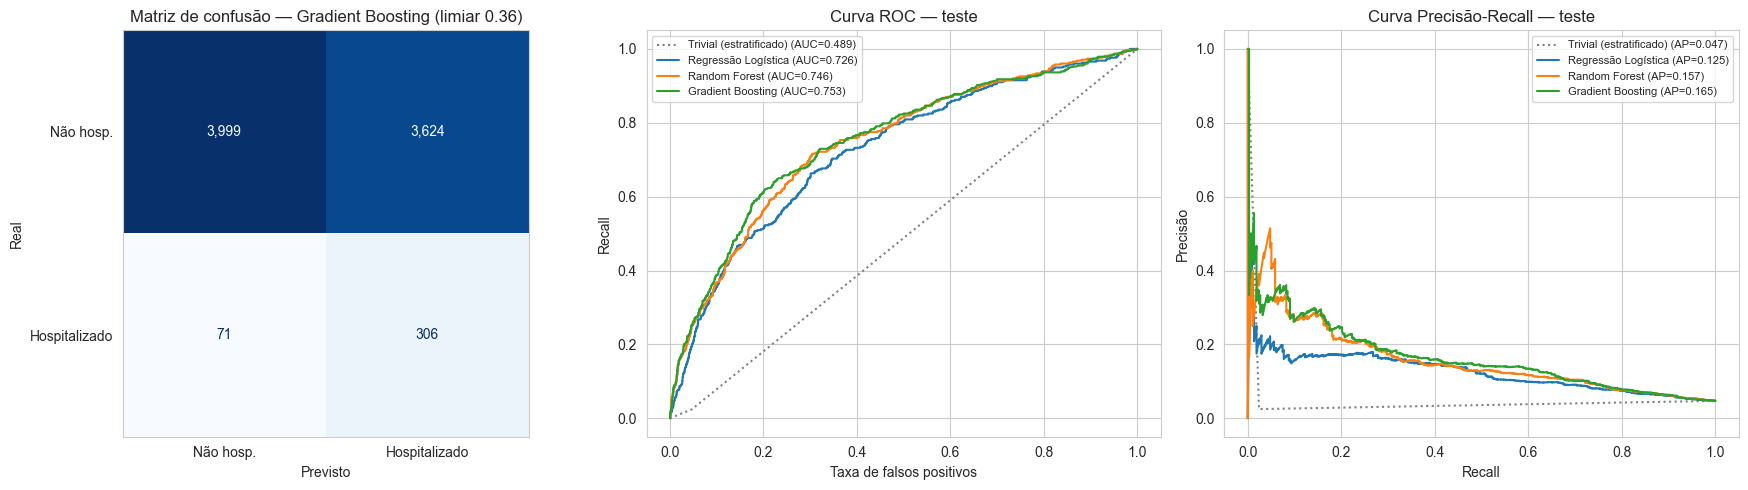

In [11]:
proba_final = probas_teste[NOME_FINAL]
pred_final = (proba_final >= LIMIAR).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, display_labels=["Não hosp.", "Hospitalizado"],
    cmap="Blues", values_format=",", ax=axes[0], colorbar=False)
axes[0].set(title=f"Matriz de confusão — {NOME_FINAL} (limiar {LIMIAR:.2f})",
            xlabel="Previsto", ylabel="Real")
axes[0].grid(False)

for nome, proba in probas_teste.items():
    estilo = {"ls": ":", "color": "gray"} if nome.startswith("Trivial") else {}
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, proba):.3f})", **estilo)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[2].plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})", **estilo)
axes[1].set(xlabel="Taxa de falsos positivos", ylabel="Recall", title="Curva ROC — teste")
axes[2].set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão-Recall — teste")
for ax in axes[1:]:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
# Intervalos de confiança de 95% por bootstrap (reamostragem do teste com reposição)
rng = np.random.RandomState(SEED)
y_arr, proba_lr = y_test.to_numpy(), probas_teste["Regressão Logística"]
amostras = []
for _ in range(N_BOOTSTRAP):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    yb, pb, predb = y_arr[idx], proba_final[idx], pred_final[idx]
    amostras.append({"AUC-ROC": roc_auc_score(yb, pb), "AUC-PR": average_precision_score(yb, pb),
                     "Recall": recall_score(yb, predb), "Precisão": precision_score(yb, predb),
                     "Δ AUC-PR vs. Reg. Logística": average_precision_score(yb, pb)
                                                    - average_precision_score(yb, proba_lr[idx])})
amostras = pd.DataFrame(amostras)

pontual = metricas_teste(y_test, proba_final, LIMIAR)
pontual["Δ AUC-PR vs. Reg. Logística"] = pontual["AUC-PR"] - average_precision_score(y_test, proba_lr)
pd.DataFrame({"Estimativa": {m: pontual[m] for m in amostras.columns},
              "IC 95% inf.": amostras.quantile(0.025),
              "IC 95% sup.": amostras.quantile(0.975)}).round(3)

,Estimativa,IC 95% inf.,IC 95% sup.
AUC-ROC,0.753,0.723,0.779
AUC-PR,0.165,0.135,0.199
Recall,0.812,0.767,0.850
Precisão,0.078,0.070,0.087
Δ AUC-PR vs. Reg. Logística,0.040,0.019,0.061


- **Sem sobreajuste:** o teste confirma a validação cruzada (AUC-ROC de 0,753 vs.
  0,752).
- **Superior ao acaso e à Regressão Logística, com significância:** a AUC-ROC
  tem IC de 0,723 a 0,779 (bem acima de 0,5), e a diferença de AUC-PR para a
  Regressão Logística tem IC de 0,019 a 0,061, que não inclui zero.
- **No limiar escolhido:** o modelo identifica 306 dos 377 hospitalizados
  (recall de 0,81, confirmando a meta) e sinaliza 49,1% dos pacientes, com
  precisão de 0,08. Entre os não sinalizados, só 1,7% foram hospitalizados
  (contra 4,7% no geral).
- **Discriminação moderada:** a ficha do SINAN não traz sinais vitais, plaquetas
  ou hematócrito, principais determinantes da internação.

## 7. Interpretabilidade

- **Razões de chances da Regressão Logística:** quanto cada fator multiplica a
  chance de hospitalização. Para as numéricas, o efeito é expresso a cada 10 anos
  de idade e a cada 1 dia de `DIAS`.
- **Importância por permutação do modelo final:** quanto a AUC-PR no teste cai
  ao embaralhar cada variável.

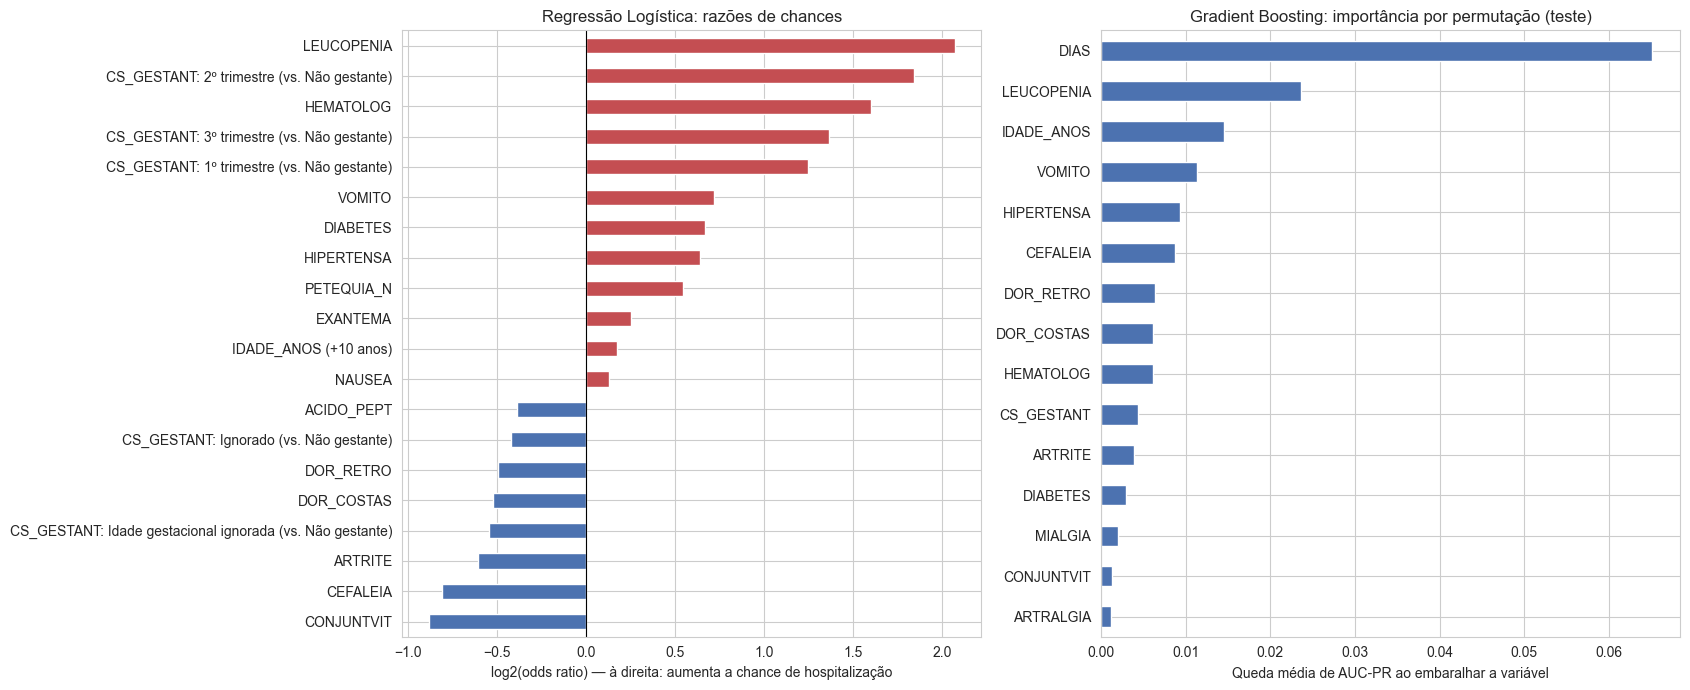

In [13]:
lr = buscas["Regressão Logística"].best_estimator_
pre, coef = lr.named_steps["pre"], lr.named_steps["modelo"].coef_[0]
escala = dict(zip(NUMERICAS, pre.named_transformers_["num"].scale_))
unidade = {"IDADE_ANOS": (10, "anos"), "DIAS": (1, "dia")}

odds = {}
for nome, b in zip(pre.get_feature_names_out(), coef):
    grupo, var = nome.split("__", 1)
    if grupo == "num":
        n, u = unidade[var]
        odds[f"{var} (+{n} {u})"] = np.exp(b / escala[var] * n)
    elif grupo == "cat":
        col, cod = var.rsplit("_", 1)
        odds[f"{col}: {ROTULOS[col].get(cod, cod)} (vs. {ROTULOS[col][REFERENCIAS[col]]})"] = np.exp(b)
    else:
        odds[var] = np.exp(b)
odds = pd.Series(odds).sort_values()
imp = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
destaque = pd.concat([odds.head(8), odds.tail(12)])
np.log2(destaque).plot(kind="barh", ax=axes[0],
                       color=["#4C72B0" if v < 1 else "#C44E52" for v in destaque])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(xlabel="log2(odds ratio) — à direita: aumenta a chance de hospitalização",
            title="Regressão Logística: razões de chances")
imp.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set(xlabel="Queda média de AUC-PR ao embaralhar a variável",
            title=f"{NOME_FINAL}: importância por permutação (teste)")
plt.tight_layout()
plt.show()

- **`DIAS` é a variável mais importante** para o Gradient Boosting, mas tem
  efeito pequeno na Regressão Logística: a relação é não linear (o risco sobe até
  ~2 semanas de doença e cai depois).
- **Fatores de risco esperados:** leucopenia, idade, vômito, hipertensão,
  diabetes, doença hematológica e gestação aumentam a chance de internação. No
  caso da gestação, isso reflete também a conduta assistencial, que dá
  acompanhamento diferenciado às gestantes.
- **Sintomas "clássicos" associados a menor chance:** cefaleia, dor
  retro-orbital, artrite e conjuntivite são típicos de casos leves. São
  associações, não efeitos causais.

## 8. Conclusões

1. O **Gradient Boosting** foi o melhor modelo: **AUC-ROC de 0,753** (IC 95%:
   0,723–0,779) e **AUC-PR de 0,165** no teste, superior ao classificador
   trivial e à Regressão Logística.
2. Com o limiar escolhido no treino, o modelo identificou **81% dos
   hospitalizados**, sinalizando 49% dos pacientes (precisão de 8%). A acurácia
   (54%) é inadequada como métrica neste problema: o trivial atinge 95%.
3. As variáveis mais informativas foram **`DIAS`**, leucopenia, idade, vômito
   e hipertensão, seguidas de outras comorbidades, como diabetes e doença hematológica.
4. `CS_RACA`, `CS_ESCOL_N` e `CS_SEXO` não foram usadas como preditoras (ver
   seção 2).
5. **Limitações:**
   - a discriminação é moderada;
   - o desfecho reflete também a conduta médica e a disponibilidade de leitos;
   - assumimos que `DIAS` e `LEUCOPENIA` estão disponíveis no primeiro atendimento;
   - as probabilidades não estão calibradas;
   - os dados são apenas de SP em 2025.

O modelo é uma **ferramenta de apoio** à triagem e não substitui o julgamento
clínico.